# **MACHINE LEARNING PROJECT**


In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [112]:
df = pd.read_csv('ford.csv')

In [113]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


# EDA


In [114]:
df.shape

(17966, 9)

In [115]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000
mean,2016.866470,12279.534844,23362.608761,113.329456,57.906980,1.350807
std,2.050336,4741.343657,19472.054349,62.012456,10.125696,0.432367
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9987.000000,30.000000,52.300000,1.000000
50%,2017.000000,11291.000000,18242.500000,145.000000,58.900000,1.200000
75%,2018.000000,15299.000000,31060.000000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


In [116]:
df.isnull().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [117]:
df.duplicated().sum()

np.int64(154)

In [118]:
df = df.drop_duplicates()
df.shape

(17812, 9)

<Axes: xlabel='price', ylabel='Count'>

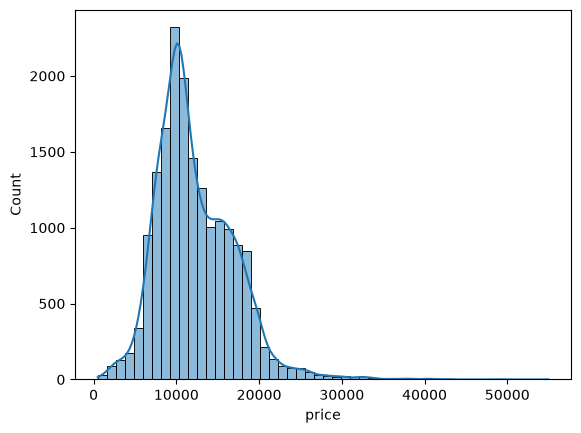

In [119]:
sns.histplot(df['price'], bins=50, kde=True)

<Axes: xlabel='price', ylabel='mileage'>

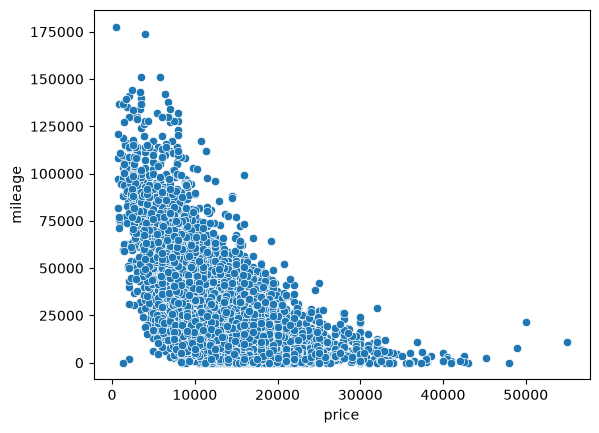

In [120]:
sns.scatterplot(y='mileage', x='price',data=df)

<Axes: xlabel='engineSize', ylabel='price'>

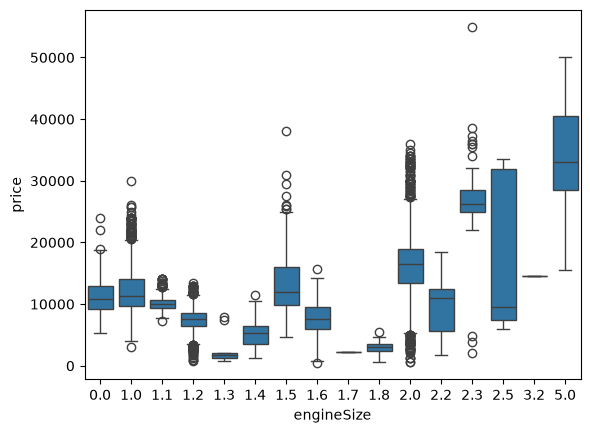

In [121]:
sns.boxplot(y='price', x='engineSize',data=df)

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22],
 [Text(0, 0, '1996'),
  Text(1, 0, '1998'),
  Text(2, 0, '2000'),
  Text(3, 0, '2002'),
  Text(4, 0, '2003'),
  Text(5, 0, '2004'),
  Text(6, 0, '2005'),
  Text(7, 0, '2006'),
  Text(8, 0, '2007'),
  Text(9, 0, '2008'),
  Text(10, 0, '2009'),
  Text(11, 0, '2010'),
  Text(12, 0, '2011'),
  Text(13, 0, '2012'),
  Text(14, 0, '2013'),
  Text(15, 0, '2014'),
  Text(16, 0, '2015'),
  Text(17, 0, '2016'),
  Text(18, 0, '2017'),
  Text(19, 0, '2018'),
  Text(20, 0, '2019'),
  Text(21, 0, '2020'),
  Text(22, 0, '2060')])

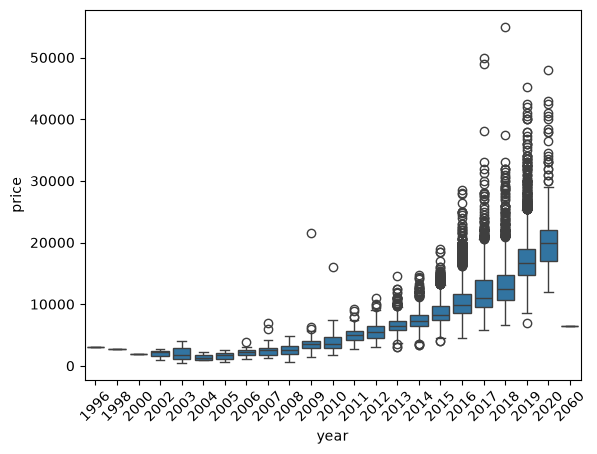

In [122]:
sns.boxplot(y='price', x='year',data=df)
plt.xticks(rotation=45)

<Axes: xlabel='price', ylabel='mpg'>

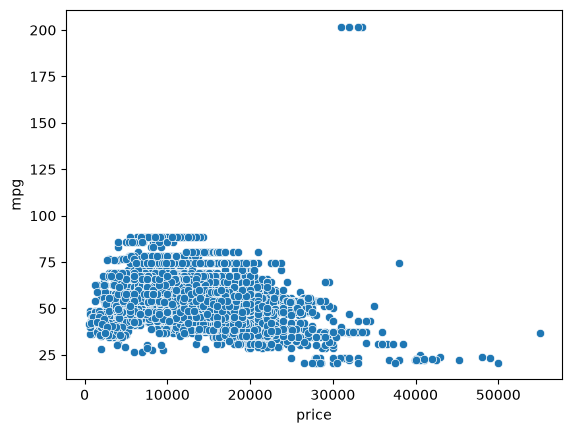

In [123]:
sns.scatterplot(y='mpg', x='price',data=df)

<Axes: xlabel='transmission', ylabel='price'>

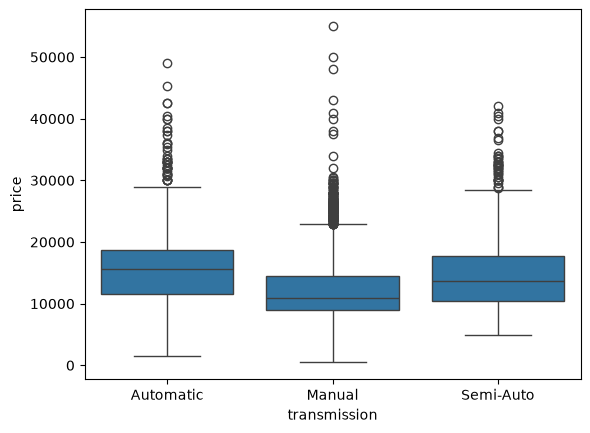

In [124]:
sns.boxplot(x='transmission', y='price',data=df)

<Axes: xlabel='fuelType', ylabel='price'>

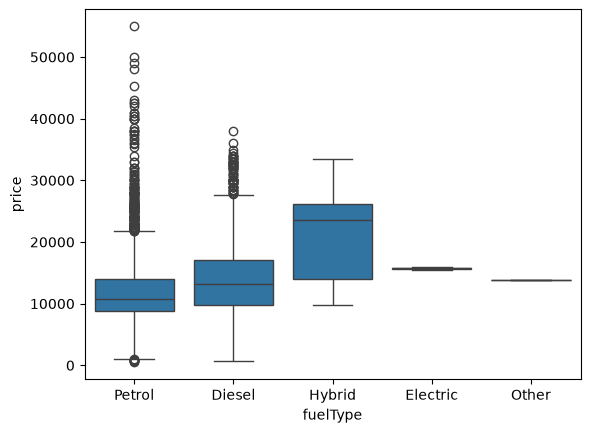

In [125]:
sns.boxplot(x='fuelType', y='price', data=df)

<Axes: >

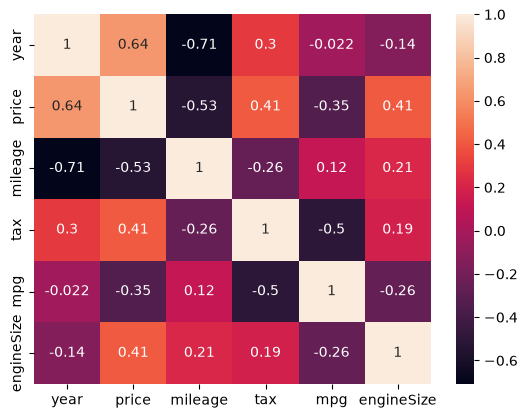

In [126]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

# FEATURE ENGINEERING AND PREPROCESSING


In [127]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [128]:
df['engSize_Category'] = pd.cut(
    df['engineSize'],
    bins=[0,1.0,2.0,3.0,float('inf')],
    labels=['Small Engine', 'Mid-Size Engine', 'Large Engine','High-Perforamnce Engine']
)

In [129]:
df['mileageLevel'] = pd.cut(
    df['mileage'],
    bins=[0,15000,40000,80000,120000,float('inf')],
    labels=['Ultra-Low Mileage','Low Mileage','Moderate Mileage','High Mileage','Very High Mileage']
)

In [130]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize', 'engSize_Category', 'mileageLevel'],
      dtype='str')

In [131]:
df_one_encode = pd.get_dummies(columns=['model','transmission','fuelType','engSize_Category','mileageLevel'],data=df,drop_first=True)

In [132]:
df_one_encode.head()

,year,price,mileage,tax,mpg,engineSize,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,...,fuelType_Hybrid,fuelType_Other,fuelType_Petrol,engSize_Category_Mid-Size Engine,engSize_Category_Large Engine,engSize_Category_High-Perforamnce Engine,mileageLevel_Low Mileage,mileageLevel_Moderate Mileage,mileageLevel_High Mileage,mileageLevel_Very High Mileage
0,2017,12000,15944,150,57.7,1.0,False,False,False,False,...,False,False,True,False,False,False,True,False,False,False
1,2018,14000,9083,150,57.7,1.0,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
2,2017,13000,12456,150,57.7,1.0,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
3,2019,17500,10460,145,40.3,1.5,False,False,False,False,...,False,False,True,True,False,False,False,False,False,False
4,2019,16500,1482,145,48.7,1.0,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [133]:
df_one_encode.columns

Index(['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize', 'model_ C-MAX',
       'model_ EcoSport', 'model_ Edge', 'model_ Escort', 'model_ Fiesta',
       'model_ Focus', 'model_ Fusion', 'model_ Galaxy', 'model_ Grand C-MAX',
       'model_ Grand Tourneo Connect', 'model_ KA', 'model_ Ka+',
       'model_ Kuga', 'model_ Mondeo', 'model_ Mustang', 'model_ Puma',
       'model_ Ranger', 'model_ S-MAX', 'model_ Streetka',
       'model_ Tourneo Connect', 'model_ Tourneo Custom',
       'model_ Transit Tourneo', 'model_Focus', 'transmission_Manual',
       'transmission_Semi-Auto', 'fuelType_Electric', 'fuelType_Hybrid',
       'fuelType_Other', 'fuelType_Petrol', 'engSize_Category_Mid-Size Engine',
       'engSize_Category_Large Engine',
       'engSize_Category_High-Perforamnce Engine', 'mileageLevel_Low Mileage',
       'mileageLevel_Moderate Mileage', 'mileageLevel_High Mileage',
       'mileageLevel_Very High Mileage'],
      dtype='str')

In [134]:
df_one_encode[['model_ C-MAX',
       'model_ EcoSport', 'model_ Edge', 'model_ Escort', 'model_ Fiesta',
       'model_ Focus', 'model_ Fusion', 'model_ Galaxy', 'model_ Grand C-MAX',
       'model_ Grand Tourneo Connect', 'model_ KA', 'model_ Ka+',
       'model_ Kuga', 'model_ Mondeo', 'model_ Mustang', 'model_ Puma',
       'model_ Ranger', 'model_ S-MAX', 'model_ Streetka',
       'model_ Tourneo Connect', 'model_ Tourneo Custom',
       'model_ Transit Tourneo', 'model_Focus', 'transmission_Manual',
       'transmission_Semi-Auto', 'fuelType_Electric', 'fuelType_Hybrid',
       'fuelType_Other', 'fuelType_Petrol', 'engSize_Category_Mid-Size Engine',
       'engSize_Category_Large Engine',
       'engSize_Category_High-Perforamnce Engine', 'mileageLevel_Low Mileage',
       'mileageLevel_Moderate Mileage', 'mileageLevel_High Mileage',
       'mileageLevel_Very High Mileage']] = df_one_encode[['model_ C-MAX',
       'model_ EcoSport', 'model_ Edge', 'model_ Escort', 'model_ Fiesta',
       'model_ Focus', 'model_ Fusion', 'model_ Galaxy', 'model_ Grand C-MAX',
       'model_ Grand Tourneo Connect', 'model_ KA', 'model_ Ka+',
       'model_ Kuga', 'model_ Mondeo', 'model_ Mustang', 'model_ Puma',
       'model_ Ranger', 'model_ S-MAX', 'model_ Streetka',
       'model_ Tourneo Connect', 'model_ Tourneo Custom',
       'model_ Transit Tourneo', 'model_Focus', 'transmission_Manual',
       'transmission_Semi-Auto', 'fuelType_Electric', 'fuelType_Hybrid',
       'fuelType_Other', 'fuelType_Petrol', 'engSize_Category_Mid-Size Engine',
       'engSize_Category_Large Engine',
       'engSize_Category_High-Perforamnce Engine', 'mileageLevel_Low Mileage',
       'mileageLevel_Moderate Mileage', 'mileageLevel_High Mileage',
       'mileageLevel_Very High Mileage']].astype(int)

In [135]:
df_one_encode.head()

,year,price,mileage,tax,mpg,engineSize,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,...,fuelType_Hybrid,fuelType_Other,fuelType_Petrol,engSize_Category_Mid-Size Engine,engSize_Category_Large Engine,engSize_Category_High-Perforamnce Engine,mileageLevel_Low Mileage,mileageLevel_Moderate Mileage,mileageLevel_High Mileage,mileageLevel_Very High Mileage
0,2017,12000,15944,150,57.7,1.0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
1,2018,14000,9083,150,57.7,1.0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,2017,13000,12456,150,57.7,1.0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,2019,17500,10460,145,40.3,1.5,0,0,0,0,...,0,0,1,1,0,0,0,0,0,0
4,2019,16500,1482,145,48.7,1.0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [136]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize', 'engSize_Category', 'mileageLevel'],
      dtype='str')

In [137]:
# LABEL ENCODING

from sklearn.preprocessing import LabelEncoder

df_label = df.copy()
selected_features = ['model','transmission', 'fuelType', 'engineSize', 'engSize_Category','mileageLevel']
for col in selected_features:
    le = LabelEncoder()
    df_label[col] = le.fit_transform(df[col])
df_label.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,engSize_Category,mileageLevel
0,5,2017,12000,0,15944,4,150,57.7,1,3,1
1,6,2018,14000,1,9083,4,150,57.7,1,3,3
2,6,2017,13000,1,12456,4,150,57.7,1,3,3
3,5,2019,17500,1,10460,4,145,40.3,6,2,3
4,5,2019,16500,0,1482,4,145,48.7,1,3,3


# MAKING MODEL


In [138]:
y = df_one_encode['price']
X_one_encode = df_one_encode.drop(columns=['price'])

In [139]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X_one_encode, y, 
    test_size=0.2,       # 20% for testing, 80% for training
    random_state=42      # Ensures the random split is reproducible
)

In [140]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](41,)","[1037.73, -0.07, -1.74,..., -0.41,1694.84,3326.7 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](41,)","['year','mileage','tax',...,'mileageLevel_Moderate Mileage', 'mileageLevel_High Mileage','mileageLevel_Very High Mileage']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.079e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,41
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(33)


In [141]:
y_pred = model.predict(X_test)

In [142]:
y_pred

array([22265.21731995, 14588.58873908, 16092.53982543, ...,
       11165.13574122, 20860.83349852, 11599.36113341], shape=(3563,))

In [143]:
y_test.head()

9891     22975
13006    18000
15284    18500
6399      9985
8182      7998
Name: price, dtype: int64

In [144]:
r2 = r2_score(y_test,y_pred)
n = X_test.shape[0]
k = X_test.shape[1]
ar2 = 1 - ((1-r2)*(n-1)) / (n-k-1)
print("r2 =",r2)
print("Adjusted r2 =",ar2)

r2 = 0.8456836273368279
Adjusted r2 = 0.8438867028042547


In [145]:
X_label = df_label.drop(columns=['price'])

In [146]:

X_train, X_test, y_train, y_test = train_test_split(
    X_label, y, 
    test_size=0.2,       # 20% for testing, 80% for training
    random_state=42      # Ensures the random split is reproducible
)

In [147]:
model2 = LinearRegression()
model2.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 52.02,1156.58,-339.05,..., 943.88,3170.91, 393.09]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['model','year','transmission',...,'engineSize','engSize_Category', 'mileageLevel']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.326e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [148]:
y_pred = model2.predict(X_test)

In [149]:
y_pred

array([17234.5539893 , 13832.81477096, 17133.89782633, ...,
       12289.35483364, 22302.15226239, 11529.46623995], shape=(3563,))

In [150]:
y_test.head()

9891     22975
13006    18000
15284    18500
6399      9985
8182      7998
Name: price, dtype: int64

In [151]:
r2 = r2_score(y_test,y_pred)
n = X_test.shape[0]
k = X_test.shape[1]
adjusted_r2 = 1- ((1 - r2)* (n-1))/(n-k-1)
print("r2 =",r2)
print("Adjusted r2 =",adjusted_r2)

r2 = 0.7262570395446787
Adjusted r2 = 0.725486366795649
